# 1-4. 소비 갭 × QR 공백 2×2 처방 유형

**입력**: `마스터_A_동.csv` (최근 12개월 2025.08~2026.07, 음식·소매 기준)
**출력**: 동별 처방 유형 + 할인 설계 유형 → `진단_2x2_처방유형.csv`

**두 층 구조**
| 층 | 결정 | 기준 |
|---|---|---|
| 1층: 2×2 | 무엇을 할지 (할인 / QR 설치 + 할인 / QR 확대) | 소비 갭 × QR 가맹률 |
| 2층: 원인 | 할인을 어떻게 설계할지 | 전환 부족 / 객단가 부족 |

| | QR 상대적 충분 | QR 상대적 부족 |
|---|---|---|
| **소비 갭 큼** | ① 할인 바로 배치 | ② QR 설치 + 할인 |
| **소비 갭 작음** | ④ 대상 아님 | ③ QR 확대 검토 |

- 1-1 수요 필터, 1-2 소비 갭, 1-3 QR 공백과 같은 기준을 사용 (모두 37개 동 안의 중앙값)
- 맨 위 설정만 바꾸면 다음 회차에도 그대로 다시 돌릴 수 있음

## 0. 설정

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from IPython.display import display

have = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in have:
        plt.rcParams['font.family'] = name; break
plt.rcParams['axes.unicode_minus'] = False
pd.options.display.float_format = '{:,.3f}'.format

FILE   = '마스터_A_동.csv'
Q_CUT  = 0.25            # 수요 필터: 방문·결제 하위 몇 % 제외 (1-1과 동일)
MODE   = 'OR'            # 수요 필터 결합 방식 (1-1과 동일)
REF    = 'median'        # 두 축 기준선: 'median'(주) / 'mean'(민감도)
# 같은 값 처리: 기준선과 정확히 같으면 '상위'(소비 갭 작음 / QR 충분)로 분류 (1-3 규칙과 동일)

SPV, CONV, AOV = '방문당소비_음식소매', '전환_음식소매', '객단가_음식소매'
QR = 'QR가맹률_음식소매'

## 1. 수요 필터 (1-1과 동일)

In [ ]:
A = pd.read_csv(FILE, encoding='utf-8-sig')
A.columns = A.columns.str.replace('﻿', '', regex=False).str.strip()

tv, tc = A['방문'].quantile(Q_CUT), A['건수_음식소매'].quantile(Q_CUT)
pv, pc = A['방문'] > tv, A['건수_음식소매'] > tc
A['수요필터_통과'] = ((pv | pc) if MODE == 'OR' else (pv & pc)).astype(int)
P = A[A['수요필터_통과'] == 1].copy()
print(f'수요 필터 통과 {len(P)}개 / 탈락 {len(A) - len(P)}개:', A.loc[A['수요필터_통과'] == 0, '행정동명'].tolist())

## 2. 두 축 판정
- **소비 갭 큼**: 방문당 소비 < 기준선
- **QR 부족**: QR 가맹률 < 기준선
- 기준선과 같으면 상위로 분류

In [ ]:
def ref(s, how=REF):
    return s.median() if how == 'median' else s.mean()

SPV_REF, QR_REF = ref(P[SPV]), ref(P[QR])
P['소비갭_큼'] = P[SPV] < SPV_REF
P['QR_부족']  = P[QR] < QR_REF
P['소비갭(로그)'] = np.log(SPV_REF) - np.log(P[SPV])    # 양수 = 기준보다 적게 씀
P['QR공백률'] = 1 - P[QR]

print(f'방문당 소비 기준선 ({REF}): {SPV_REF:,.0f}원 → 소비 갭 큼 {P["소비갭_큼"].sum()}개')
print(f'QR 가맹률 기준선 ({REF}): {QR_REF:.2%} → QR 부족 {P["QR_부족"].sum()}개')

## 3. 원인 분해 (1-2 셀 10-2와 동일)
방문당 소비 = 전환 × 객단가. 기준(37개 동 기하평균) 대비 더 많이 부족한 쪽을 원인으로 봄.

In [ ]:
P['갭_전환']   = np.log(P[CONV]).mean() - np.log(P[CONV])
P['갭_객단가'] = np.log(P[AOV]).mean()  - np.log(P[AOV])
P['원인'] = np.where(P['갭_전환'] >= P['갭_객단가'], '전환형', '객단가형')

## 4. 처방 유형 배정

| 유형 | 처방 | 할인 설계 (소비 갭 큰 동만) |
|---|---|---|
| ① 할인 바로 배치 | 기존 QR로 할인 시행 | 전환형 → 문턱 낮은 정률 할인 / 객단가형 → 최소 결제금액 조건 할인 |
| ② QR 설치 + 할인 | QR 가맹 확대 후 할인 | 위와 동일 |
| ③ QR 확대 검토 | 할인 대상은 아니나 QR 보급 필요 | - |
| ④ 대상 아님 | - | - |

In [ ]:
TYPE = {(True, False): '① 할인 바로 배치', (True, True): '② QR 설치 + 할인',
        (False, True): '③ QR 확대 검토',   (False, False): '④ 대상 아님'}
P['처방유형'] = [TYPE[(g, q)] for g, q in zip(P['소비갭_큼'], P['QR_부족'])]

DESIGN = {'전환형': '문턱 낮은 정률 할인 (소액 결제도 적용)', '객단가형': '최소 결제금액 조건 할인'}
P['할인설계'] = np.where(P['소비갭_큼'], P['원인'].map(DESIGN), '-')
P.loc[~P['소비갭_큼'], '원인'] = '-'

summary = (P.groupby(['처방유형', '원인']).agg(동수=('행정동명', 'size'),
           행정동=('행정동명', lambda s: ', '.join(s))).reset_index())
display(summary)

## 5. 경계 동 표시
- **QR 경계**: 평균 기준으로 바꾸면 QR 분류가 달라지는 동
- **소비 갭 경계**: 방문당 소비가 기준선과 같은 동
- **원인 경계**: 소비 갭은 큰데 원인 분해 기준(기하평균)으로는 부족하지 않은 동 (두 원인 합이 음수)

In [ ]:
qr_mean = P[QR] < P[QR].mean()
flags = []
for i, r in P.iterrows():
    f = []
    if qr_mean[i] != r['QR_부족']: f.append('QR 경계')
    if r[SPV] == SPV_REF: f.append('소비갭 경계')
    if r['소비갭_큼'] and (r['갭_전환'] + r['갭_객단가'] < 0): f.append('원인 경계')
    flags.append(', '.join(f))
P['경계'] = flags
display(P.loc[P['경계'] != '', ['행정동명', SPV, QR, '처방유형', '원인', '경계']])

## 6. 2×2 시각화
표와 같은 배치: **위 = 소비 갭 큼, 오른쪽 = QR 부족**. 점 모양 = 원인 (● 전환형, ■ 객단가형).

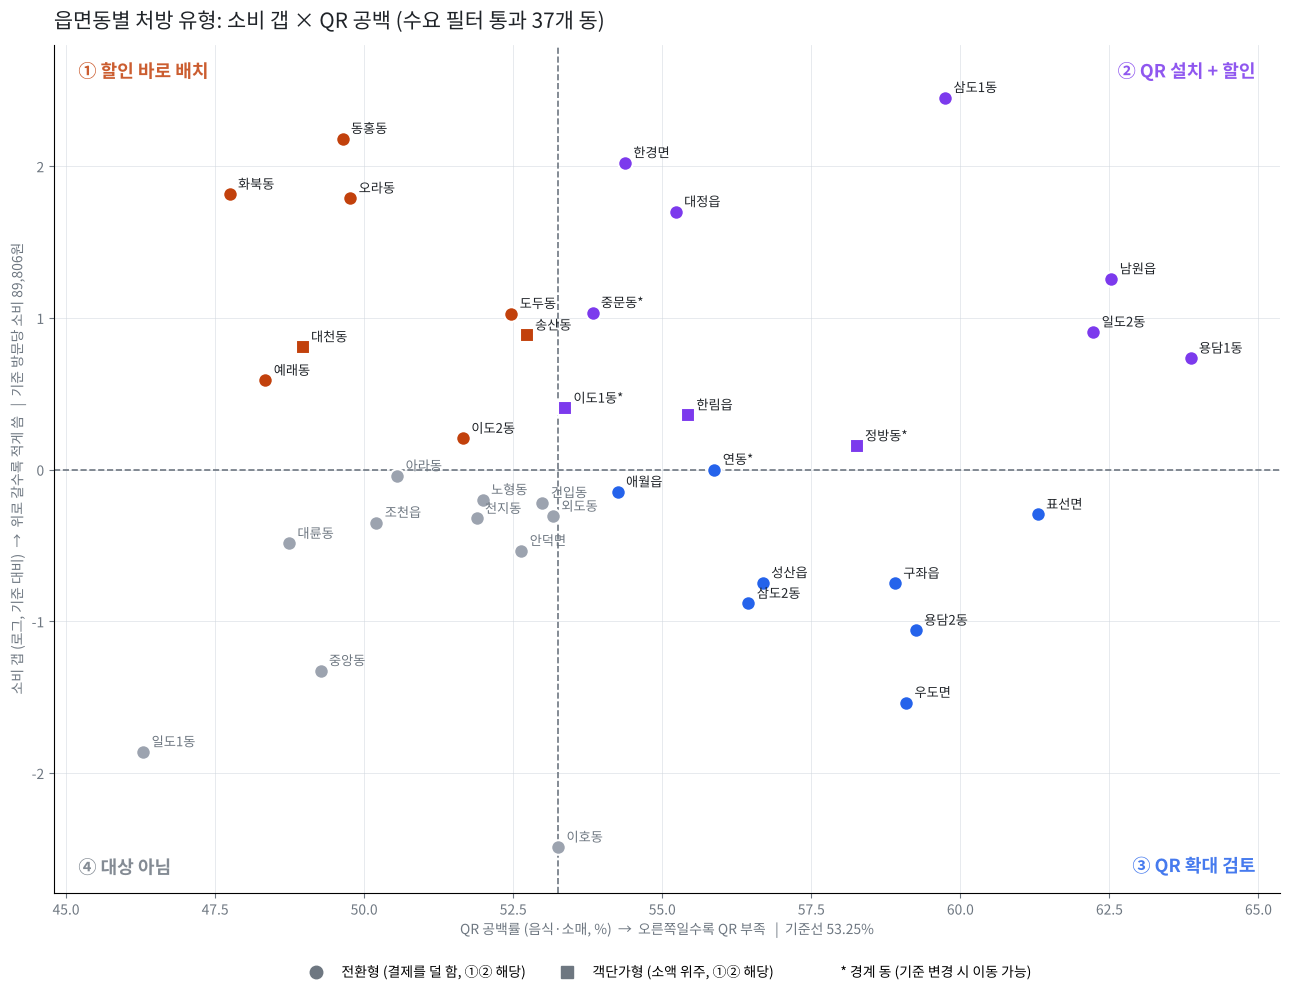

In [ ]:
INK, MUTED, GRID = '#1f2328', '#6e7781', '#d0d7de'
COL = {'① 할인 바로 배치': '#c2410c', '② QR 설치 + 할인': '#7c3aed',
       '③ QR 확대 검토': '#2563eb', '④ 대상 아님': '#9ca3af'}
MRK = {'전환형': 'o', '객단가형': 's', '-': 'o'}

fig, ax = plt.subplots(figsize=(13, 10))
x, y = P['QR공백률'] * 100, P['소비갭(로그)']
x0 = (1 - QR_REF) * 100

# 사분면 배경
xl = (x.min() - 1.5, x.max() + 1.5); yl = (y.min() - 0.3, y.max() + 0.35)
ax.axvline(x0, color=MUTED, lw=1.2, ls='--', zorder=1)
ax.axhline(0, color=MUTED, lw=1.2, ls='--', zorder=1)

for t, s in P.groupby('처방유형'):
    for cause, ss in s.groupby('원인'):
        ax.scatter(ss['QR공백률'] * 100, ss['소비갭(로그)'], s=110, marker=MRK[cause],
                   color=COL[t], edgecolor='white', linewidth=1.5, zorder=3)
for _, r in P.iterrows():
    star = '*' if r['경계'] else ''
    ax.annotate(r['행정동명'] + star, (r['QR공백률'] * 100, r['소비갭(로그)']),
                xytext=(6, 4), textcoords='offset points', fontsize=9.5,
                color=INK if r['처방유형'] != '④ 대상 아님' else MUTED)

pad = dict(fontsize=13, fontweight='bold', alpha=0.85)
ax.text(0.02, 0.98, '① 할인 바로 배치', transform=ax.transAxes, ha='left', va='top', color=COL['① 할인 바로 배치'], **pad)
ax.text(0.98, 0.98, '② QR 설치 + 할인', transform=ax.transAxes, ha='right', va='top', color=COL['② QR 설치 + 할인'], **pad)
ax.text(0.98, 0.02, '③ QR 확대 검토', transform=ax.transAxes, ha='right', va='bottom', color=COL['③ QR 확대 검토'], **pad)
ax.text(0.02, 0.02, '④ 대상 아님', transform=ax.transAxes, ha='left', va='bottom', color=MUTED, **pad)

ax.set_xlim(xl); ax.set_ylim(yl)
ax.set_xlabel(f'QR 공백률 (음식·소매, %)  →  오른쪽일수록 QR 부족   |  기준선 {x0:.2f}%', color=MUTED)
ax.set_ylabel(f'소비 갭 (로그, 기준 대비)  →  위로 갈수록 적게 씀   |  기준 방문당 소비 {SPV_REF:,.0f}원', color=MUTED)
ax.set_title('읍면동별 처방 유형: 소비 갭 × QR 공백 (수요 필터 통과 37개 동)', fontsize=15, color=INK, loc='left', pad=12)
ax.grid(color=GRID, lw=0.6, alpha=0.6); ax.set_axisbelow(True)
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
ax.tick_params(colors=MUTED)
ax.legend(handles=[Line2D([0], [0], marker='o', ls='', color=MUTED, ms=9, label='전환형 (결제를 덜 함, ①② 해당)'),
                   Line2D([0], [0], marker='s', ls='', color=MUTED, ms=9, label='객단가형 (소액 위주, ①② 해당)'),
                   Line2D([0], [0], ls='', label='* 경계 동 (기준 변경 시 이동 가능)')],
          loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig('2x2_처방유형.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. 처방 유형별 요약

In [ ]:
cnt = P['처방유형'].value_counts().reindex(list(TYPE.values())).fillna(0).astype(int)
tbl = pd.DataFrame({'동 수': cnt,
                    '외국인 방문 비중(%)': P.groupby('처방유형')['방문'].sum().reindex(cnt.index) / P['방문'].sum() * 100,
                    '외국인 소비 비중(%)': P.groupby('처방유형')['금액_음식소매'].sum().reindex(cnt.index) / P['금액_음식소매'].sum() * 100})
display(tbl.round(1))

## 8. 민감도: 기준을 바꾸면 어느 동이 움직이나

In [ ]:
def classify(q_cut=Q_CUT, ref_spv='median', ref_qr='median'):
    a = A.copy()
    pv, pc = a['방문'] > a['방문'].quantile(q_cut), a['건수_음식소매'] > a['건수_음식소매'].quantile(q_cut)
    p = a[pv | pc].copy()
    g = p[SPV] < ref(p[SPV], ref_spv); q = p[QR] < ref(p[QR], ref_qr)
    return pd.Series([TYPE[(gi, qi)] for gi, qi in zip(g, q)], index=p['행정동명'])

base = classify()
rows = []
for name, kw in [('수요 필터 하위 20%', dict(q_cut=0.20)), ('수요 필터 하위 30%', dict(q_cut=0.30)),
                 ('QR 기준선 = 평균', dict(ref_qr='mean'))]:
    alt = classify(**kw)
    common = base.index.intersection(alt.index)
    moved = [f'{d}: {base[d][:1]}→{alt[d][:1]}' for d in common if base[d] != alt[d]]
    added = [d for d in alt.index if d not in base.index]
    dropped = [d for d in base.index if d not in alt.index]
    rows.append({'변경': name, '분류 유지율(%)': (len(common) - len(moved)) / len(common) * 100,
                 '이동한 동': ', '.join(moved) or '-', '새로 포함': ', '.join(added) or '-', '제외됨': ', '.join(dropped) or '-'})
display(pd.DataFrame(rows).round(1))
print('※ 소비 갭 기준선 = 평균은 방문당 소비 분포가 크게 치우쳐(평균이 중앙값보다 57% 높음) 민감도에서 제외')

## 9. 결과 저장

In [ ]:
OUT = P[['행정동코드', '행정동명', '권역', '방문', '금액_음식소매', SPV, CONV, AOV, QR, 'QR공백률',
         '소비갭_큼', 'QR_부족', '처방유형', '원인', '할인설계', '경계']].sort_values(['처방유형', SPV])
OUT.to_csv('진단_2x2_처방유형.csv', index=False, encoding='utf-8-sig')
print('저장: 진단_2x2_처방유형.csv', OUT.shape)
display(OUT.reset_index(drop=True))